# 02 · How many categories? Discovering k from the abstracts

The task asks for the best number of categories, not a fixed one. We let the text decide:

1. Embed every `title. abstract` with **SPECTER2** (scientific encoder) and **MiniLM** (general
   encoder, robustness check). Neither model saw arXiv labels, so the analysis is not circular.
2. **Label-free view:** k-means on paper embeddings for k = 2…80, scored with silhouette and
   Davies-Bouldin (internal) and NMI/ARI against arXiv's own groups/archives (external).
3. **Taxonomy-guided view:** Ward-cluster the fine arXiv categories by their centroid embeddings.
   Cutting the dendrogram at k merges real categories into k classes, scored by how separable the
   papers are (silhouette, Davies-Bouldin, and macro-F1 of a linear probe on held-out papers).
4. Every criterion votes for a k in [5, 80]; the reported best k is the median vote.

Runs on a Kaggle T4 GPU (~25 min).

In [1]:
import glob
import shutil
import sys
from pathlib import Path


def add_src_to_path():
    hits = glob.glob("/kaggle/input/**/taxonomy.py", recursive=True)
    if hits:
        pkg = Path("/tmp/pkg/src")
        shutil.copytree(Path(hits[0]).parent, pkg, dirs_exist_ok=True)
        sys.path.insert(0, str(pkg.parent))
    else:
        sys.path.insert(0, str(Path.cwd().parent))


add_src_to_path()

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy.cluster.hierarchy import dendrogram
from sklearn.metrics import adjusted_rand_score

from src import discover_k as dk
from src import taxonomy, viz
from src.utils import FIG_DIR, RESULTS_DIR, DATA_DIR, ensure_dirs, find_input, save_json, set_seed

set_seed()
ensure_dirs()
viz.apply_style()
assert torch.cuda.is_available(), "No GPU: set Accelerator to GPU (needs a phone-verified Kaggle account)"

K_MIN, K_MAX = 5, 80
KS = list(range(2, 31)) + list(range(35, K_MAX + 1, 5))

train = pd.read_parquet(find_input("train.parquet"))
val = pd.read_parquet(find_input("val.parquet"))
print(len(train), len(val), train["fine"].nunique(), "fine categories")

59200 7400 148 fine categories


## 1. Embeddings

In [2]:
emb = {}
for enc in dk.ENCODERS:
    X = dk.embed(pd.concat([train["text"], val["text"]]), enc)
    emb[enc] = (X[: len(train)], X[len(train):])
    np.save(DATA_DIR / f"emb_{enc}_train.npy", emb[enc][0])
    np.save(DATA_DIR / f"emb_{enc}_val.npy", emb[enc][1])
    print(enc, X.shape)

config.json:   0%|          | 0.00/754 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/453 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/228k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/717k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

minilm (66600, 384)


## 2. Sweeps

In [3]:
reference = {lvl: train[lvl].to_numpy() for lvl in ["group", "archive", "fine"]}
results = {}
for enc, (X_tr, X_va) in emb.items():
    R_tr = dk.reduce(X_tr)
    km = dk.kmeans_sweep(R_tr, KS, reference)
    Z, cats = dk.category_linkage(X_tr, train["fine"].to_numpy())
    tx = dk.taxonomy_sweep(X_tr, train["fine"].to_numpy(), X_va, val["fine"].to_numpy(), Z, cats, KS)
    choice = dk.choose_k(km, tx, Z, K_MIN, K_MAX)
    results[enc] = {"kmeans": km, "taxonomy": tx, "Z": Z, "cats": cats, **choice}
    km.to_csv(RESULTS_DIR / f"k_sweep_kmeans_{enc}.csv", index=False)
    tx.to_csv(RESULTS_DIR / f"k_sweep_taxonomy_{enc}.csv", index=False)
    print(enc, choice)

kmeans k=  2 sil=0.1352 db=3.532


kmeans k=  3 sil=0.1347 db=3.182


kmeans k=  4 sil=0.1391 db=3.040


kmeans k=  5 sil=0.1312 db=3.241


kmeans k=  6 sil=0.1361 db=3.081


...

ward k= 65 sil=0.0121 f1=0.613


ward k= 70 sil=0.0113 f1=0.607


ward k= 75 sil=0.0103 f1=0.605


ward k= 80 sil=0.0083 f1=0.597


minilm {'votes': {'kmeans_silhouette_max': 7, 'kmeans_davies_bouldin_min': 50, 'taxonomy_silhouette_max': 5, 'taxonomy_davies_bouldin_min': 26, 'taxonomy_probe_f1_knee': 25, 'dendrogram_merge_gap': 7}, 'best_k': 16}


PosixPath('/kaggle/working/reports/figures/fig08_k_selection.png')

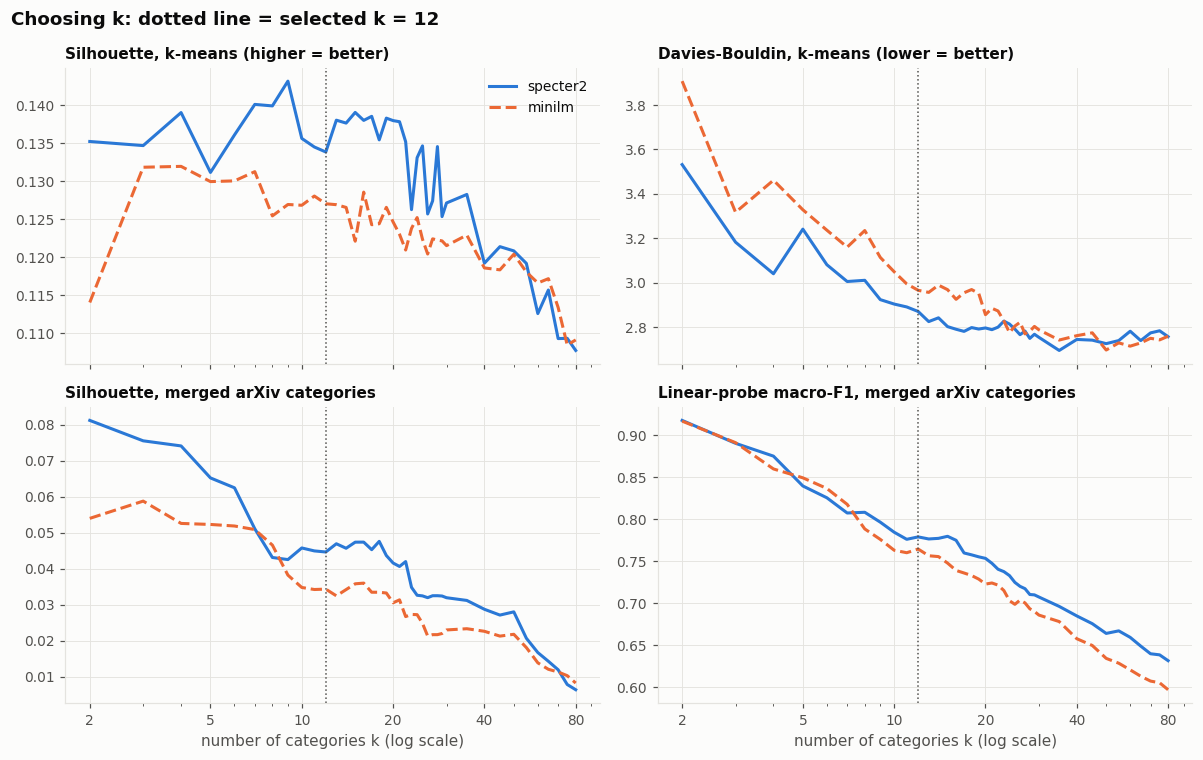

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
panels = [
    ("silhouette", "kmeans", "Silhouette, k-means (higher = better)"),
    ("davies_bouldin", "kmeans", "Davies-Bouldin, k-means (lower = better)"),
    ("silhouette", "taxonomy", "Silhouette, merged arXiv categories"),
    ("probe_macro_f1", "taxonomy", "Linear-probe macro-F1, merged arXiv categories"),
]
for ax, (metric, view, title) in zip(axes.flat, panels):
    for enc, ls in zip(results, ["-", "--"]):
        d = results[enc][view]
        ax.plot(d["k"], d[metric], ls=ls, color=viz.ACCENT if enc == "specter2" else viz.SERIES[1], label=enc)
    ax.axvline(results["specter2"]["best_k"], color=viz.TEXT_2, lw=1, ls=":")
    ax.set_title(title, fontsize=10)
    ax.set_xscale("log")
    ax.set_xticks([2, 5, 10, 20, 40, 80], ["2", "5", "10", "20", "40", "80"])
axes[0, 0].legend()
for ax in axes[1]:
    ax.set_xlabel("number of categories k (log scale)")
fig.suptitle(f"Choosing k: dotted line = selected k = {results['specter2']['best_k']}", x=0.01, ha="left",
             fontweight="semibold")
fig.tight_layout()
viz.save(fig, "fig08_k_selection", FIG_DIR)

PosixPath('/kaggle/working/reports/figures/fig09_nmi_vs_taxonomy.png')

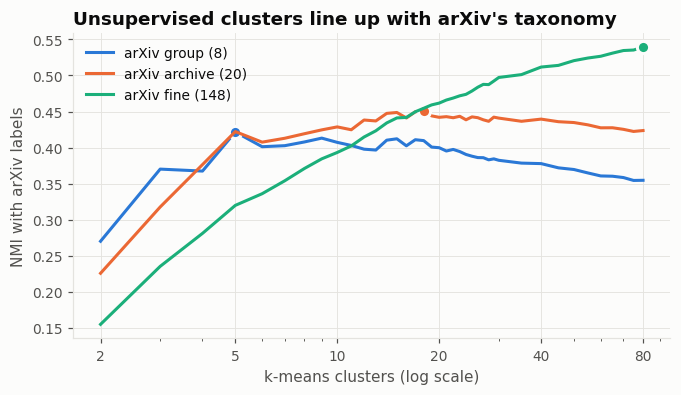

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.6))
d = results["specter2"]["kmeans"]
for lvl, color in zip(["group", "archive", "fine"], viz.SERIES[:3]):
    ax.plot(d["k"], d[f"nmi_{lvl}"], color=color, label=f"arXiv {lvl} ({train[lvl].nunique()})")
    kbest = int(d.loc[d[f"nmi_{lvl}"].idxmax(), "k"])
    ax.plot(kbest, d[f"nmi_{lvl}"].max(), "o", color=color, ms=8, mec=viz.SURFACE, mew=2)
ax.set_xscale("log")
ax.set_xticks([2, 5, 10, 20, 40, 80], ["2", "5", "10", "20", "40", "80"])
ax.set_xlabel("k-means clusters (log scale)")
ax.set_ylabel("NMI with arXiv labels")
ax.set_title("Unsupervised clusters line up with arXiv's taxonomy")
ax.legend()
viz.save(fig, "fig09_nmi_vs_taxonomy", FIG_DIR)

## 3. The selected k and its categories

In [6]:
best = results["specter2"]
K = best["best_k"]
mapping = dk.cut(best["Z"], best["cats"], K)
sizes = train["fine"].value_counts()


def cluster_name(members):
    """Name a cluster by its dominant arXiv group and its three largest member categories."""
    members = sorted(members, key=lambda c: -sizes.get(c, 0))
    groups = pd.Series([taxonomy.group_of(c) for c in members]).value_counts()
    more = f" +{len(members) - 3}" if len(members) > 3 else ""
    return f"{groups.index[0]}: {', '.join(members[:3])}{more}"


clusters = {}
for cid in range(K):
    members = [c for c, i in mapping.items() if i == cid]
    clusters[cid] = {"name": cluster_name(members), "members": members,
                     "n_train": int(train["fine"].isin(members).sum())}
pd.DataFrame(clusters).T[["name", "n_train"]]

,name,n_train
0,"Computer Science: cs.AR, cs.DC, cs.ET +6",3600
1,"Computer Science: cs.CV, cs.GR, cs.LG +11",5600
2,"Quantitative Finance: q-fin.CP, q-fin.MF, q-fi...",2800
3,"Computer Science: cs.AI, cs.CL, cs.CR +6",3600
4,"Statistics: cs.DL, cs.GT, cs.SI +12",6000
5,"Mathematics: math.AC, math.AG, math.AT +11",5600
6,"Computer Science: cs.CC, cs.CG, cs.DM +11",5600
7,"Physics: astro-ph.CO, astro-ph.EP, astro-ph.GA +3",2400
8,"Physics: gr-qc, hep-ex, hep-lat +12",6000
9,"Physics: cond-mat.mes-hall, cond-mat.mtrl-sci,...",4800


In [7]:
# How close is the data-driven taxonomy to arXiv's? Compare category-level groupings.
cats = best["cats"]
agreement = {
    "ARI(cut at k=#groups, arXiv groups)": adjusted_rand_score(
        [taxonomy.group_of(c) for c in cats], [dk.cut(best["Z"], cats, train["group"].nunique())[c] for c in cats]),
    "ARI(cut at k=#archives, arXiv archives)": adjusted_rand_score(
        [taxonomy.archive_of(c) for c in cats], [dk.cut(best["Z"], cats, train["archive"].nunique())[c] for c in cats]),
}
agreement

{'ARI(cut at k=#groups, arXiv groups)': 0.26682529644162745,
 'ARI(cut at k=#archives, arXiv archives)': 0.27020577670317236}

PosixPath('/kaggle/working/reports/figures/fig10_category_dendrogram.png')

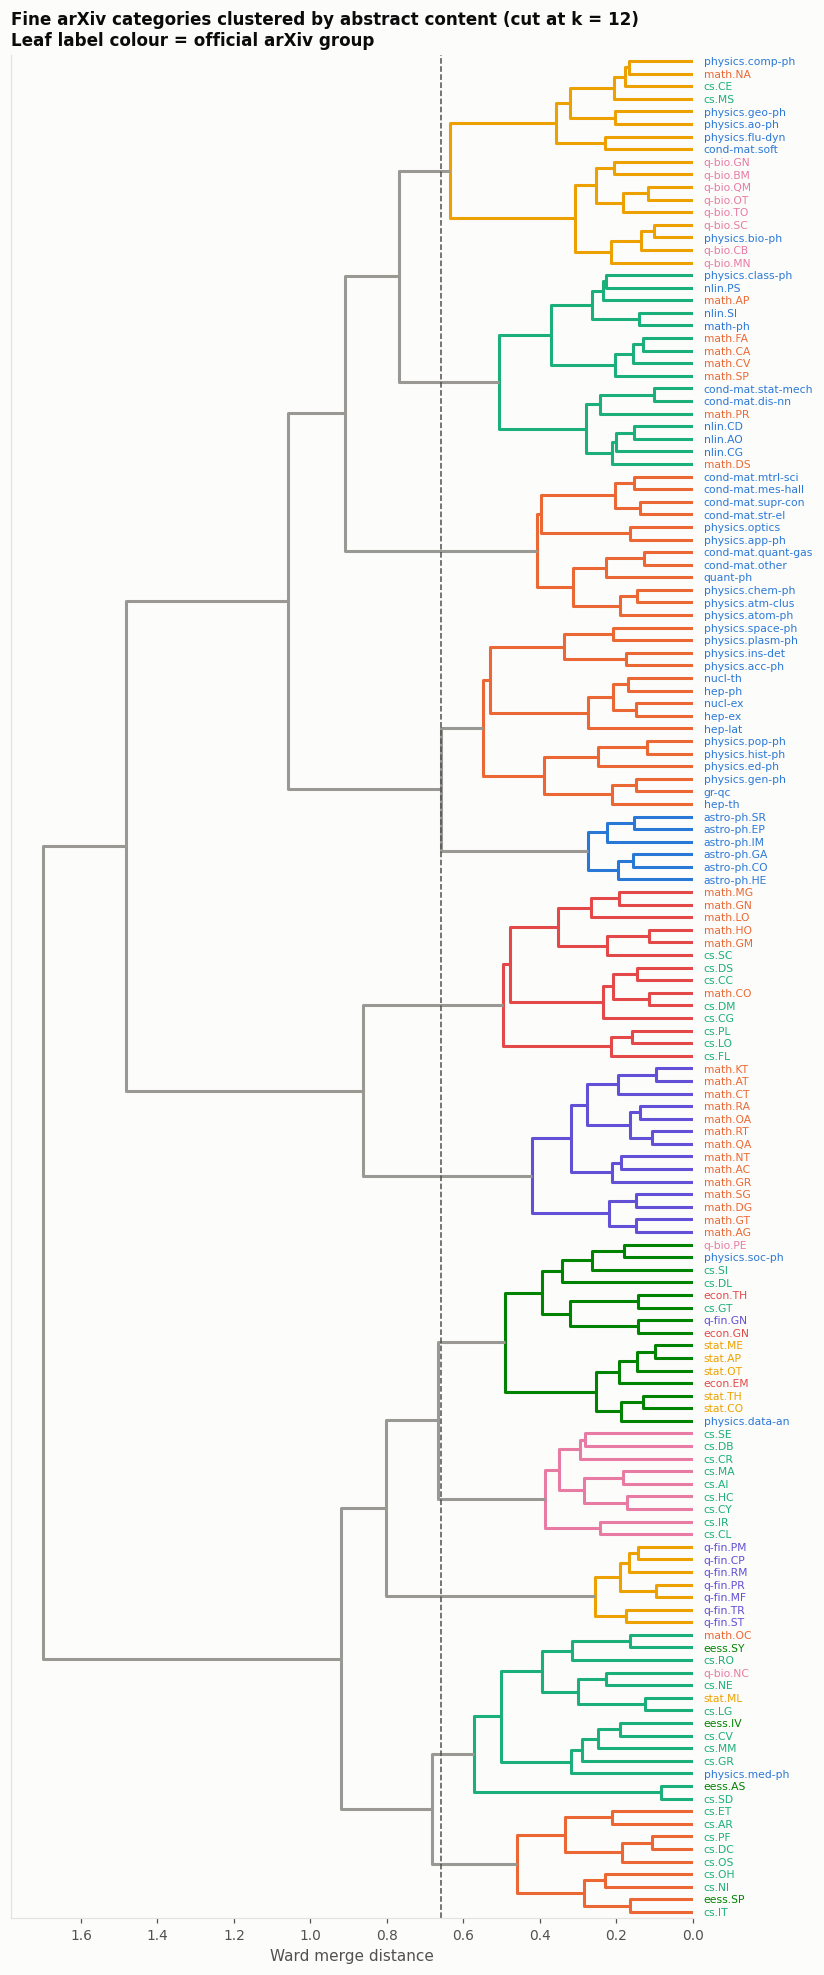

In [8]:
fig, ax = plt.subplots(figsize=(8, 22))
dendrogram(best["Z"], labels=list(cats), orientation="left", leaf_font_size=7, ax=ax,
           color_threshold=best["Z"][-(K - 1), 2], above_threshold_color=viz.NEUTRAL)
for lbl in ax.get_ymajorticklabels():
    lbl.set_color(viz.GROUP_COLORS[taxonomy.group_of(lbl.get_text())])
ax.axvline(best["Z"][-(K - 1), 2], color=viz.TEXT_2, ls="--", lw=1)
ax.set_xlabel("Ward merge distance")
ax.set_title(f"Fine arXiv categories clustered by abstract content (cut at k = {K})\n"
             "Leaf label colour = official arXiv group", fontsize=11)
ax.grid(False)
viz.save(fig, "fig10_category_dendrogram", FIG_DIR)

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


PosixPath('/kaggle/working/reports/figures/fig11_umap.png')

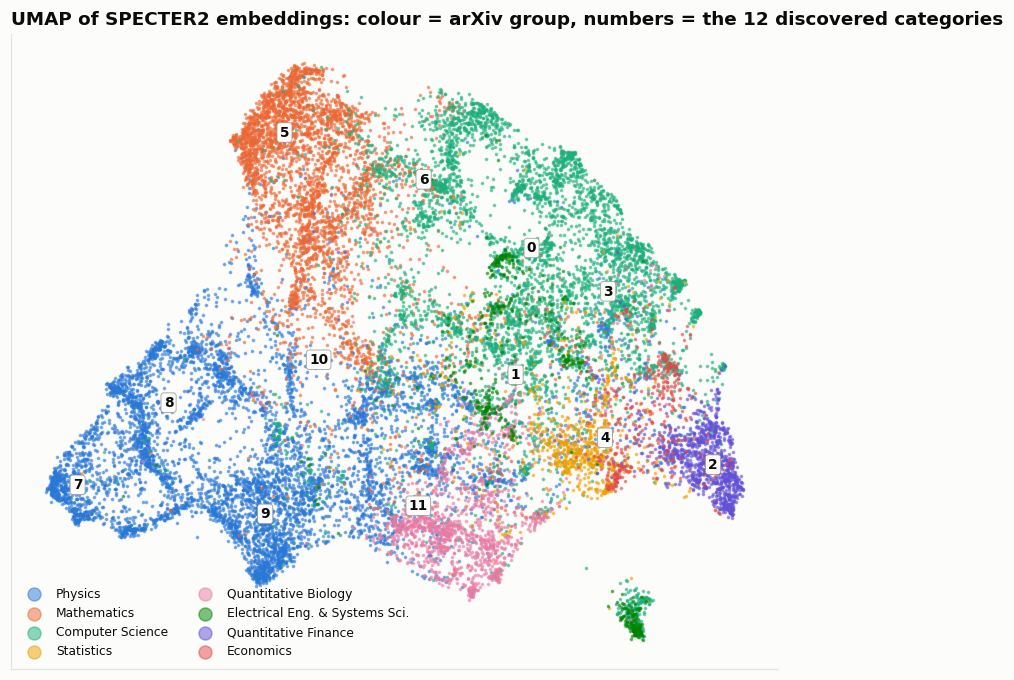

In [9]:
import umap

X_tr = emb["specter2"][0]
rng = np.random.default_rng(0)
sub = rng.choice(len(X_tr), size=min(20000, len(X_tr)), replace=False)
U = umap.UMAP(n_neighbors=30, min_dist=0.1, metric="cosine", random_state=42).fit_transform(X_tr[sub])
g = train["group"].to_numpy()[sub]
cl = train["fine"].map(mapping).to_numpy()[sub]

fig, ax = plt.subplots(figsize=(9, 7.5))
for grp in viz.GROUP_ORDER:
    m = g == grp
    ax.scatter(U[m, 0], U[m, 1], s=2, alpha=0.5, color=viz.GROUP_COLORS[grp], label=grp, rasterized=True)
for cid in range(K):
    m = cl == cid
    if m.sum() > 50:
        cx, cy = np.median(U[m], axis=0)
        ax.text(cx, cy, str(cid), fontsize=9, fontweight="bold", ha="center", va="center",
                bbox=dict(boxstyle="round,pad=0.2", fc=viz.SURFACE, ec=viz.NEUTRAL, lw=0.5))
ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
ax.set_title(f"UMAP of SPECTER2 embeddings: colour = arXiv group, numbers = the {K} discovered categories")
ax.legend(markerscale=6, loc="lower left", fontsize=8, ncol=2)
viz.save(fig, "fig11_umap", FIG_DIR)

In [10]:
save_json({
    "best_k": K,
    "votes": best["votes"],
    "robustness_minilm": {"best_k": results["minilm"]["best_k"], "votes": results["minilm"]["votes"]},
    "taxonomy_agreement_ari": agreement,
    "mapping": mapping,
    "clusters": clusters,
}, RESULTS_DIR / "best_k.json")
print("best k =", K, "| MiniLM best k =", results["minilm"]["best_k"])

best k = 12 | MiniLM best k = 16
